# Análise de inadimplência em cartões de crédito

**Julia Ragi** · Análise de dados<br>
**Dados:** [Default of Credit Card Clients](https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients) (UCI Machine Learning Repository, CC BY 4.0)<br>
**Ferramentas:** Python, pandas, matplotlib, scikit-learn

---

## Resumo executivo

**Problema.** Um banco emissor de cartões quer identificar, com antecedência, quais clientes vão deixar de pagar a fatura,
para agir antes da perda sem prejudicar os bons clientes.

**Principais achados**
- **22,1%** dos 30 mil clientes ficaram inadimplentes no mês seguinte ao histórico analisado.
- **O histórico de atrasos é o sinal mais forte.** Quem atrasou nos 6 meses tem **70,3%** de inadimplência, contra **11,7%** de quem nunca atrasou.
- **O sinal aparece cedo.** Em abril, 24,3% dos futuros inadimplentes já tinham fatura atrasada, contra 6,3% dos demais.
- **Limites baixos concentram mais risco:** 31,8% de inadimplência em limites de até NT\$ 50 mil, contra 13,3% acima de NT\$ 300 mil.
- **O risco maior dos jovens vem do limite, não da idade.** Clientes de até 25 anos têm a maior taxa (26,7%), mas, ajustando pelo limite, ela cai para **22,1%**, igual à média geral.
- **Um modelo simples prioriza bem os clientes de risco:** os 20% apontados como mais arriscados concentram **49,7%** dos inadimplentes (AUC de 0,755).

**Recomendações**
1. Cobrança preventiva a partir do **primeiro mês de atraso**.
2. Usar o modelo para **priorizar** as ações de cobrança e de revisão de limite.
3. Oferecer **renegociação** a quem paga menos de 10% da fatura (27,5% de inadimplência).

## 1. Contexto e perguntas

O dataset reúne 30 mil clientes de um banco de Taiwan, com dados cadastrais, limite de crédito e histórico mensal de
faturas, pagamentos e atrasos.

Neste projeto, o **perfil do cliente** é visto em duas partes: os **dados cadastrais** (idade, escolaridade, sexo e
estado civil) e o **comportamento de pagamento** (histórico de faturas, pagamentos e atrasos). Em crédito, essa
separação é comum: são as variáveis cadastrais e as variáveis comportamentais.

O dataset tem dois períodos:

| Período | Conteúdo | Papel na análise |
|---|---|---|
| Abril a setembro de 2005 | Histórico mês a mês de cada cliente | Informações usadas para analisar e prever |
| Outubro de 2005 | Se o cliente ficou inadimplente (sim/não) | Resultado a prever |

A coluna do resultado se chama `default payment next month`. A documentação não cita o mês, mas, como o histórico
termina em setembro, o mês seguinte é outubro.

**Perguntas de negócio**
1. Qual é a taxa de inadimplência e como ela se distribui?
2. O histórico de pagamento antecipa a inadimplência? Com quanta antecedência?
3. Uso do limite e pagamento parcial da fatura indicam risco?
4. Os dados cadastrais (idade e escolaridade) importam depois de considerar limite e comportamento de pagamento?
5. Um modelo simples ajuda o banco a priorizar clientes? Com que ganho?

## 2. Dados e preparação

In [1]:
# @title Configuração do ambiente e identidade visual { display-mode: "form" }
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

from matplotlib.colors import LinearSegmentedColormap
from matplotlib import font_manager
import logging
logging.getLogger('matplotlib.font_manager').setLevel(logging.ERROR)   # esconde avisos sobre fontes

pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

# ===== Identidade visual =====
# Cores: para mudar o visual de todos os gráficos, altere apenas os códigos abaixo
COR_ACIMA   = '#4B2461'   # destaque: grupos acima da média (mais risco)
COR_ABAIXO  = '#A985CF'   # grupos abaixo da média (menos risco)
FUNDO       = '#FAF8FC'   # fundo dos gráficos
COR_TITULO  = '#4B2461'   # títulos
TINTA       = '#2A2233'   # textos e valores
TINTA_SUAVE = '#6F667C'   # eixos e rótulos
CINZA       = '#A79FB2'   # linha de referência (média)
LINHA       = '#E3DCEC'   # linhas de grade
EIXO        = '#D5CCE0'   # linhas dos eixos
CMAP_SEQ = LinearSegmentedColormap.from_list('tema', ['#F6F2FA', '#DED1EF', '#A985CF', '#4B2461'])   # mapas de calor (claro -> escuro)
NOME_ACIMA, NOME_ABAIXO = 'ameixa', 'lilás'

# Fonte preferida: usada quando já está instalada no computador (deixe '' para não usar)
FONTE_PREFERIDA = ''
# Fontes do Google Fonts, usadas quando a preferida não está instalada (ex.: no Colab):
# (arquivo no repositório oficial, configuração da fonte variável, uso)
FONTES = [
    ('ofl/ibmplexsans/IBMPlexSans%5Bwdth,wght%5D.ttf', {'wght': 400, 'wdth': 100}, 'texto'),
    ('ofl/fraunces/Fraunces%5BSOFT,WONK,opsz,wght%5D.ttf', {'wght': 600, 'opsz': 24, 'SOFT': 0, 'WONK': 0}, 'titulo'),
]

# Baixa e prepara as fontes. Se algo falhar, os gráficos usam a fonte padrão e tudo continua funcionando.
FONTE = {'texto': 'DejaVu Sans', 'titulo': 'DejaVu Sans'}
instaladas = {f.name for f in font_manager.fontManager.ttflist}
if FONTE_PREFERIDA and FONTE_PREFERIDA in instaladas:
    FONTE = {'texto': FONTE_PREFERIDA, 'titulo': FONTE_PREFERIDA}
    FONTES = []
    print(f'Usando a fonte {FONTE_PREFERIDA}, instalada neste computador.')
try:
    import urllib.request
    from fontTools.ttLib import TTFont
    from fontTools.varLib.instancer import instantiateVariableFont
    for arquivo, eixos, uso in FONTES:
        urllib.request.urlretrieve('https://raw.githubusercontent.com/google/fonts/main/' + arquivo, 'fonte_variavel.ttf')
        # gera uma versão fixa da fonte variável (com o peso escolhido) e dá a ela um nome próprio,
        # para o texto e os títulos não se confundirem quando usam a mesma família
        fonte = TTFont('fonte_variavel.ttf')
        if 'fvar' in fonte:   # fonte variável: fixa o peso escolhido
            fonte = instantiateVariableFont(fonte, eixos)
        familia = fonte['name'].getBestFamilyName() + (' Texto' if uso == 'texto' else ' Titulo')
        for registro in fonte['name'].names:
            if registro.nameID in (1, 4, 16):
                registro.string = familia
        # Algumas fontes usam algarismos "antigos" (de alturas variadas) por padrão;
        # quando existem algarismos alinhados (.lf), usamos esses, que são mais fáceis de ler em gráficos
        glifos = set(fonte.getGlyphOrder())
        for tabela in fonte['cmap'].tables:
            for digito in '0123456789':
                glifo = tabela.cmap.get(ord(digito))
                if glifo and glifo + '.lf' in glifos:
                    tabela.cmap[ord(digito)] = glifo + '.lf'
        fonte.save(f'fonte_{uso}.ttf')
        font_manager.fontManager.addfont(f'fonte_{uso}.ttf')
        FONTE[uso] = font_manager.fontManager.ttflist[-1].name
    if FONTES:
        print(f"Fontes carregadas: {FONTE['texto']} (texto) e {FONTE['titulo']} (títulos).")
except Exception as erro:
    print(f'Não foi possível carregar as fontes ({erro}). Usando a fonte padrão.')
FONTE_TEXTO, FONTE_TITULO = FONTE['texto'], FONTE['titulo']

plt.rcParams.update({
    'figure.figsize': (10, 5), 'figure.facecolor': FUNDO, 'axes.facecolor': FUNDO, 'savefig.facecolor': FUNDO,
    'font.family': FONTE_TEXTO, 'font.size': 11, 'text.color': TINTA,
    'axes.titlecolor': COR_TITULO, 'axes.titlesize': 15, 'axes.titleweight': 'normal', 'axes.titlepad': 14,
    'axes.labelcolor': TINTA_SUAVE, 'xtick.color': TINTA_SUAVE, 'ytick.color': TINTA_SUAVE,
    'axes.edgecolor': EIXO, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'axes.grid.axis': 'y', 'grid.color': LINHA, 'grid.linewidth': 0.8,
    'legend.frameon': False, 'axes.axisbelow': True, 'lines.linewidth': 2.2, 'lines.markersize': 8,
})

# Pasta onde os gráficos serão salvos (para usar no README do GitHub)
os.makedirs('images', exist_ok=True)
print('Ambiente pronto!')

Fontes carregadas: IBM Plex Sans Texto (texto) e Fraunces Titulo (títulos).
Ambiente pronto!


In [2]:
# Lê o arquivo local, se existir; caso contrário, baixa direto do UCI
ARQUIVO_LOCAL = 'default of credit card clients.xls'
if os.path.exists(ARQUIVO_LOCAL):
    df_bruto = pd.read_excel(ARQUIVO_LOCAL, header=1)
else:
    !pip install -q ucimlrepo
    from ucimlrepo import fetch_ucirepo
    df_bruto = fetch_ucirepo(id=350).data.original
print(f'{df_bruto.shape[0]:,} clientes e {df_bruto.shape[1]} colunas')

30,000 clientes e 25 colunas


In [3]:
NOMES = ['LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE',
         'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6',
         'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6',
         'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6']

def padronizar_colunas(dados):
    dados = dados.copy()
    dados = dados.rename(columns={f'X{i}': nome for i, nome in enumerate(NOMES, start=1)})
    dados = dados.rename(columns={'PAY_0': 'PAY_1', 'Y': 'DEFAULT',
                                  'default payment next month': 'DEFAULT',
                                  'default.payment.next.month': 'DEFAULT'})
    # Remove uma eventual linha de cabeçalho repetida e garante que tudo é numérico
    dados = dados[pd.to_numeric(dados['LIMIT_BAL'], errors='coerce').notna()]
    return dados.apply(pd.to_numeric).reset_index(drop=True)

df = padronizar_colunas(df_bruto)
df.head()

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_1,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,DEFAULT
0,1,20000,2,2,1,24,2,2,-1,-1,-2,-2,3913,3102,689,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,0,2,2682,1725,2682,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,0,0,29239,14027,13559,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,0,0,46990,48233,49291,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,0,0,8617,5670,35835,20940,19146,19131,2000,36681,10000,9000,689,679,0


### Qualidade dos dados e tratamento
- **Sem valores nulos nem IDs duplicados.**
- **Categorias não documentadas:** `EDUCATION` tem os códigos 0, 5 e 6, e `MARRIAGE` tem o código 0. Foram agrupados em "Outros".
- **Nome inconsistente:** a coluna de status de setembro se chama `PAY_0`, mas a seguinte é `PAY_2`. Foi renomeada para `PAY_1`.
- **Códigos de pagamento:** -2, -1 e 0 indicam pagamento em dia (sem uso, fatura integral ou mínimo); valores de 1 a 9 indicam meses de atraso.
- **Faturas negativas** (6,4% dos clientes) representam saldo credor e foram mantidas.

In [4]:
df['EDUCATION'] = df['EDUCATION'].replace({0: 4, 5: 4, 6: 4})
df['MARRIAGE']  = df['MARRIAGE'].replace({0: 3})

MESES = {1: 'Set', 2: 'Ago', 3: 'Jul', 4: 'Jun', 5: 'Mai', 6: 'Abr'}

for i in MESES:
    df[f'atraso_mes_{i}'] = df[f'PAY_{i}'].clip(lower=0)

df[[f'atraso_mes_{i}' for i in MESES]].describe().loc[['mean', 'max']]

df['sexo']         = df['SEX'].map({1: 'Masculino', 2: 'Feminino'})
df['escolaridade'] = df['EDUCATION'].map({1: 'Pós-graduação', 2: 'Curso superior', 3: 'Ensino médio', 4: 'Outros'})
df['estado_civil'] = df['MARRIAGE'].map({1: 'Casado(a)', 2: 'Solteiro(a)', 3: 'Outros'})
df[['sexo', 'escolaridade', 'estado_civil']].isna().sum()   # deve ser tudo 0

sexo            0
escolaridade    0
estado_civil    0
dtype: int64

### Variáveis criadas
| Variável | Cálculo | O que representa |
|---|---|---|
| `uso_limite` | fatura de setembro ÷ limite | Quanto do limite está em uso |
| `meses_em_atraso` | meses com atraso, de 6 | Frequência de atrasos |
| `status_ultimo_mes` | categoria do status de setembro | Situação mais recente |
| `pct_fatura_paga` | total pago ÷ total das faturas do mês anterior | Se o cliente paga a fatura inteira ou só parte |
| faixas | idade, limite (até 50 mil, 100 mil, 200 mil, 300 mil e acima), uso e pagamento | Comparação entre grupos |

In [5]:
colunas_atraso = [f'atraso_mes_{i}' for i in MESES]

# Uso do limite
df['uso_limite'] = df['BILL_AMT1'] / df['LIMIT_BAL']

# Histórico de atrasos
df['meses_em_atraso'] = (df[colunas_atraso] > 0).sum(axis=1)
df['atraso_maximo']   = df[colunas_atraso].max(axis=1)
df['status_ultimo_mes'] = pd.cut(df['PAY_1'], bins=[-np.inf, 0, 1, 2, np.inf],
                                 labels=['Em dia', '1 mês de atraso', '2 meses de atraso', '3+ meses de atraso'])

# Percentual da fatura pago
# O pagamento feito em um mês quita a fatura do mês anterior. Por isso comparamos
# os pagamentos de set→mai (PAY_AMT1 a 5) com as faturas de ago→abr (BILL_AMT2 a 6).
total_pago    = df[[f'PAY_AMT{i}' for i in range(1, 6)]].sum(axis=1)
total_faturas = df[[f'BILL_AMT{i}' for i in range(2, 7)]].clip(lower=0).sum(axis=1)
df['pct_fatura_paga'] = np.where(total_faturas > 0, total_pago / total_faturas, np.nan)
df['sem_fatura'] = (total_faturas <= 0).astype(int)

df[['uso_limite', 'meses_em_atraso', 'atraso_maximo', 'pct_fatura_paga']].describe()

,uso_limite,meses_em_atraso,atraso_maximo,pct_fatura_paga
count,"30,000.00","30,000.00","30,000.00","28,594.00"
mean,0.42,0.83,0.68,0.42
std,0.41,1.55,1.07,2.97
min,-0.62,0.00,0.00,0.00
25%,0.02,0.00,0.00,0.05
50%,0.31,0.00,0.00,0.10
75%,0.83,1.00,2.00,0.78
max,6.46,6.00,8.00,376.12


In [6]:
df['faixa_etaria'] = pd.cut(df['AGE'], bins=[0, 25, 35, 45, 55, 120],
                            labels=['Até 25', '26–35', '36–45', '46–55', '56+'])

# Faixas de limite com valores fixos (em NT$). Cada valor de limite cai em uma única faixa;
# por isso as faixas têm tamanhos diferentes. Os intervalos incluem o valor final: "Baixo" vai de mais de 50 mil até 100 mil.
df['faixa_limite'] = pd.cut(df['LIMIT_BAL'], bins=[0, 50_000, 100_000, 200_000, 300_000, np.inf],
                            labels=['Muito baixo', 'Baixo', 'Médio', 'Alto', 'Muito alto'])

df['faixa_uso_limite'] = pd.cut(df['uso_limite'], bins=[-np.inf, 0, .3, .7, 1, np.inf],
                                labels=['Sem uso', 'Até 30%', '30–70%', '70–100%', 'Acima do limite'])

df['faixa_pagamento'] = pd.cut(df['pct_fatura_paga'], bins=[-np.inf, .1, .5, .99, np.inf],
                               labels=['Menos de 10%', '10–50%', '50–99%', 'Quitou tudo'])
df['faixa_pagamento'] = df['faixa_pagamento'].cat.add_categories('Sem fatura').fillna('Sem fatura')

print('Limites (NT$) de cada faixa:')
print(df.groupby('faixa_limite', observed=True)['LIMIT_BAL'].agg(['min', 'max', 'count']))

Limites (NT$) de cada faixa:
                 min      max  count
faixa_limite                        
Muito baixo    10000    50000   7676
Baixo          60000   100000   4822
Médio         110000   200000   7880
Alto          210000   300000   5059
Muito alto    310000  1000000   4563


## 3. Análise exploratória

A métrica central é a **taxa de inadimplência por grupo**, comparada com a taxa geral. Barras na cor ameixa estão
acima da média; na cor lilás, abaixo. O **risco vs. média** (também chamado de lift) é a taxa do grupo dividida pela taxa geral: 1,5x significa 50% mais inadimplência que a média.
Nas tabelas, `clientes` é o total de clientes do grupo e `inadimplentes` é quantos deles ficaram inadimplentes.

Taxa geral de inadimplência: 22.12%


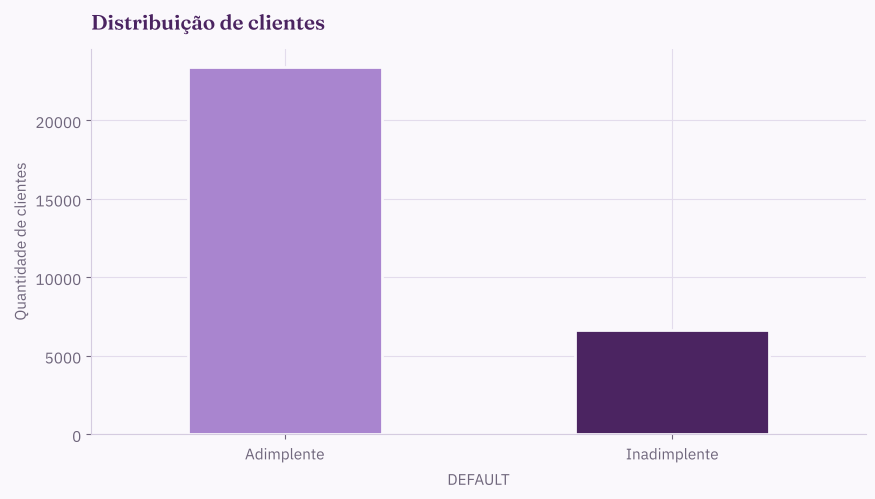

In [7]:
taxa_geral = df['DEFAULT'].mean()
print(f'Taxa geral de inadimplência: {taxa_geral:.2%}')

df['DEFAULT'].value_counts().rename({0: 'Adimplente', 1: 'Inadimplente'}).plot(
    kind='bar', color=[COR_ABAIXO, COR_ACIMA], rot=0, edgecolor=FUNDO, linewidth=2)
plt.title('Distribuição de clientes', loc='left', fontfamily=FONTE_TITULO)
plt.ylabel('Quantidade de clientes')
plt.show()

In [8]:
def taxa_por_grupo(coluna, titulo, ordenar=False, salvar=None):
    """Calcula e plota a taxa de inadimplência por categoria de uma coluna."""
    tabela = (df.groupby(coluna, observed=True)['DEFAULT']
                .agg(taxa_inadimplencia='mean', clientes='count', inadimplentes='sum'))
    tabela = tabela[tabela['clientes'] >= 50]          # ignora grupos muito pequenos
    if ordenar:
        tabela = tabela.sort_values('taxa_inadimplencia', ascending=False)

    cores = [COR_ACIMA if t > taxa_geral else COR_ABAIXO for t in tabela['taxa_inadimplencia']]
    ax = tabela['taxa_inadimplencia'].plot(kind='bar', color=cores, edgecolor=FUNDO, linewidth=2, width=0.7,
                                           rot=20 if max(len(str(r)) for r in tabela.index) > 8 else 0)
    ax.axhline(taxa_geral, color=CINZA, linestyle='--')
    ax.grid(axis='x', visible=False)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
    ax.set_title(titulo, loc='left', fontfamily=FONTE_TITULO)
    ax.set_ylabel('Taxa de inadimplência'); ax.set_xlabel('')
    ax.legend(handles=[Patch(color=COR_ACIMA, label='Acima da média'), Patch(color=COR_ABAIXO, label='Abaixo da média'),
                       Line2D([], [], color=CINZA, linestyle='--', label=f'Média geral ({taxa_geral:.1%})')],
              loc='upper left', bbox_to_anchor=(1.01, 1))
    for i, v in enumerate(tabela['taxa_inadimplencia']):
        ax.text(i, v, f'{v:.1%}', ha='center', va='bottom', fontsize=10, color=TINTA)
    plt.tight_layout()
    if salvar:
        plt.savefig(f'images/{salvar}.png', dpi=120, bbox_inches='tight')
    plt.show()

    tabela['risco_vs_media'] = tabela['taxa_inadimplencia'] / taxa_geral
    # clientes = total de clientes do grupo; inadimplentes = quantos deles ficaram inadimplentes
    return tabela.style.format({'taxa_inadimplencia': '{:.1%}', 'clientes': '{:,}', 'inadimplentes': '{:,}',
                                'risco_vs_media': '{:.2f}x'})

### 3.1 Histórico de pagamento: o sinal mais forte

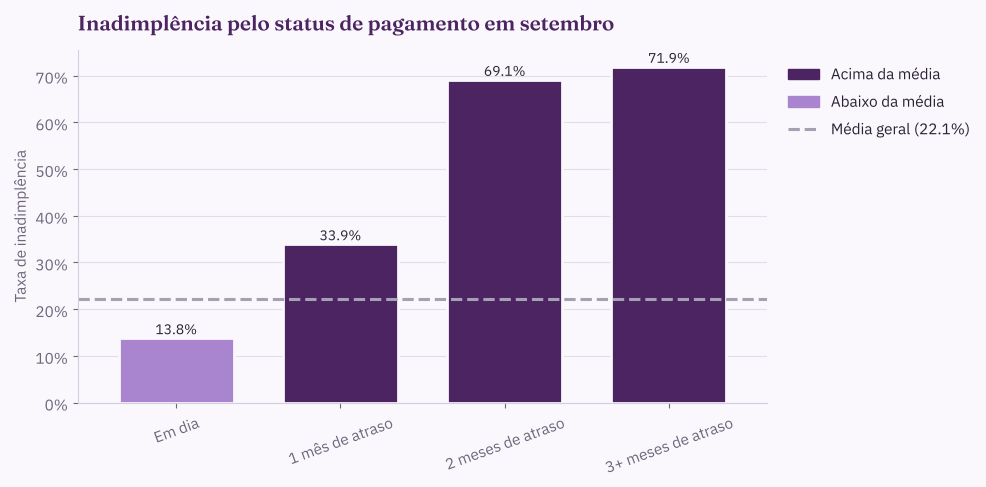

,taxa_inadimplencia,clientes,inadimplentes,risco_vs_media
status_ultimo_mes,,,,
Em dia,13.8%,"23,182","3,207",0.63x
1 mês de atraso,33.9%,"3,688","1,252",1.53x
2 meses de atraso,69.1%,"2,667","1,844",3.13x
3+ meses de atraso,71.9%,463,333,3.25x


In [9]:
taxa_por_grupo('status_ultimo_mes', 'Inadimplência pelo status de pagamento em setembro', salvar='04_status_ultimo_mes')

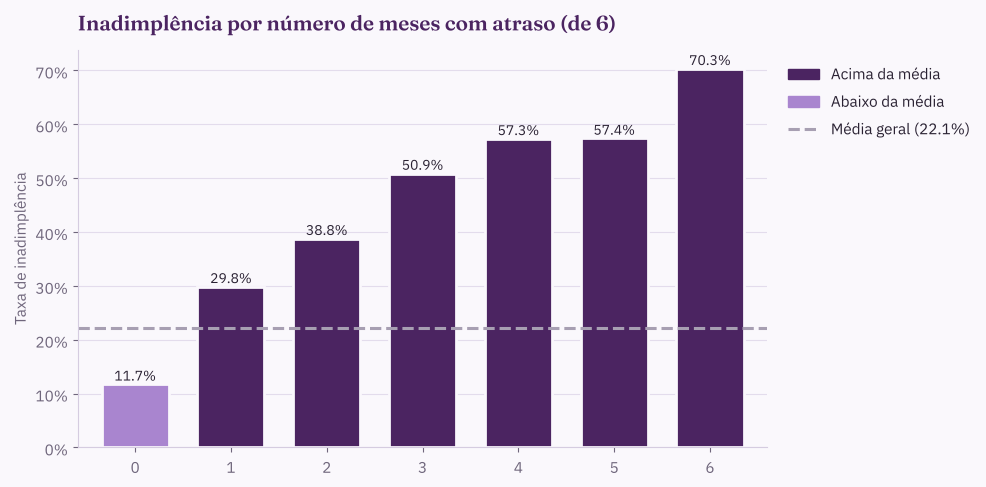

,taxa_inadimplencia,clientes,inadimplentes,risco_vs_media
meses_em_atraso,,,,
0,11.7%,"19,931","2,334",0.53x
1,29.8%,"4,426","1,320",1.35x
2,38.8%,"1,899",736,1.75x
3,50.9%,"1,154",587,2.30x
4,57.3%,951,545,2.59x
5,57.4%,298,171,2.59x
6,70.3%,"1,341",943,3.18x


In [10]:
taxa_por_grupo('meses_em_atraso', 'Inadimplência por número de meses com atraso (de 6)', salvar='05_meses_em_atraso')

**Achado.** Os dois gráficos olham o atraso de formas diferentes e contam a mesma história:
- **Situação em setembro** (último mês do histórico): quem estava em dia teve 13,8% de inadimplência; com 1 mês de
  atraso, 33,9%; com 2 meses, 69,1% (3,1 vezes a média).
- **Frequência nos 6 meses:** quem nunca atrasou teve 11,7%; quem atrasou nos 6 meses, 70,3%. A taxa sobe a cada mês
  de atraso acumulado.

Os grupos "sem atraso" têm taxas diferentes (13,8% e 11,7%) porque olham períodos diferentes: estar em dia em
setembro não significa nunca ter atrasado antes.

### 3.2 O atraso aparece meses antes
Os clientes são separados pelo que aconteceu em outubro. Para cada mês, o gráfico mostra a porcentagem de cada grupo
que estava com fatura atrasada naquele mês.

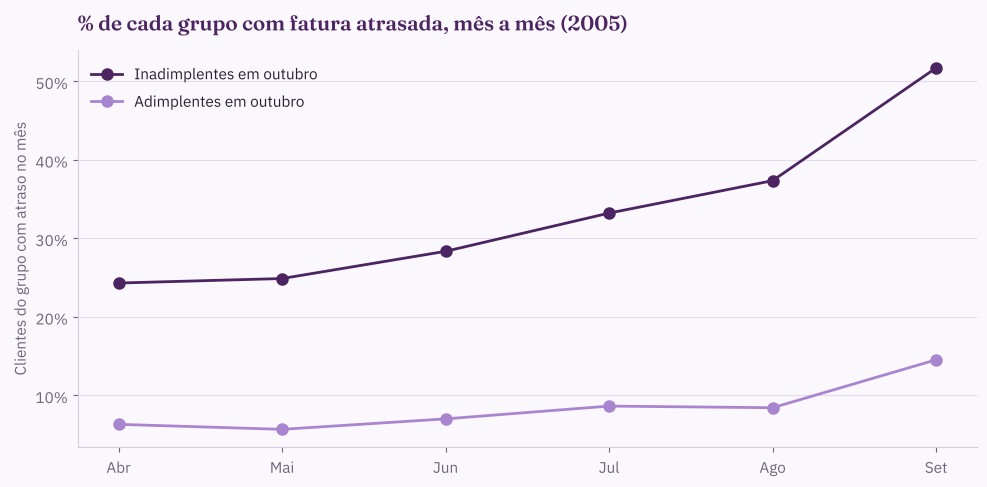

,Inadimplentes em outubro,Adimplentes em outubro
Abr,24.3%,6.3%
Mai,24.8%,5.6%
Jun,28.3%,7.0%
Jul,33.2%,8.6%
Ago,37.3%,8.4%
Set,51.7%,14.5%


In [11]:
ordem = [6, 5, 4, 3, 2, 1]   # do mais antigo (abril) para o mais recente (setembro)
evolucao = pd.DataFrame({
    grupo: [(df.loc[df['DEFAULT'] == valor, f'atraso_mes_{i}'] > 0).mean() for i in ordem]
    for grupo, valor in [('Inadimplentes em outubro', 1), ('Adimplentes em outubro', 0)]
}, index=[MESES[i] for i in ordem])

ax = evolucao.plot(marker='o', linewidth=2, color=[COR_ACIMA, COR_ABAIXO])
ax.grid(axis='x', visible=False)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_title('% de cada grupo com fatura atrasada, mês a mês (2005)', loc='left', fontfamily=FONTE_TITULO)
ax.set_ylabel('Clientes do grupo com atraso no mês'); ax.set_xlabel('')
plt.tight_layout()
plt.savefig('images/06_evolucao_atrasos.png', dpi=120, bbox_inches='tight')
plt.show()
evolucao.style.format('{:.1%}')

**Achado.** Em abril, 24,3% dos clientes que ficariam inadimplentes já tinham fatura atrasada, contra 6,3% dos que
pagaram. A diferença cresce mês a mês e chega a 51,7% contra 14,5% em setembro: há tempo para agir.

### 3.3 Uso do limite e pagamento da fatura

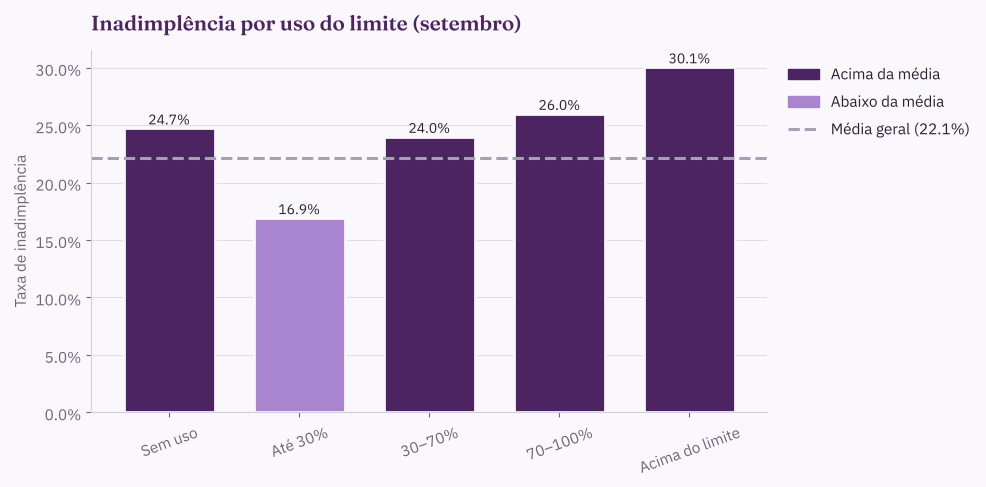

,taxa_inadimplencia,clientes,inadimplentes,risco_vs_media
faixa_uso_limite,,,,
Sem uso,24.7%,"2,598",643,1.12x
Até 30%,16.9%,"12,195","2,065",0.77x
30–70%,24.0%,"5,685","1,365",1.09x
70–100%,26.0%,"7,407","1,927",1.18x
Acima do limite,30.1%,"2,115",636,1.36x


In [12]:
taxa_por_grupo('faixa_uso_limite', 'Inadimplência por uso do limite (setembro)', salvar='07_uso_limite')

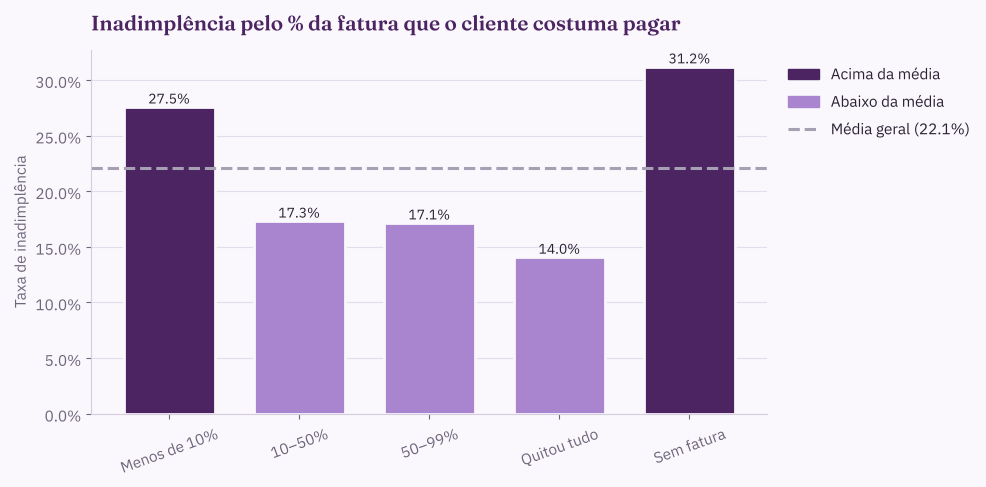

,taxa_inadimplencia,clientes,inadimplentes,risco_vs_media
faixa_pagamento,,,,
Menos de 10%,27.5%,"14,127","3,891",1.25x
10–50%,17.3%,"5,484",948,0.78x
50–99%,17.1%,"3,184",545,0.77x
Quitou tudo,14.0%,"5,799",814,0.63x
Sem fatura,31.2%,"1,406",438,1.41x


In [13]:
taxa_por_grupo('faixa_pagamento', 'Inadimplência pelo % da fatura que o cliente costuma pagar', salvar='08_pct_fatura_paga')

**Achado.** Quem usa mais que o limite tem 30,1% de inadimplência, contra 16,9% de quem usa até 30%. Quem paga menos
de 10% da fatura tem 27,5%, quase o dobro de quem quita tudo (14,0%).

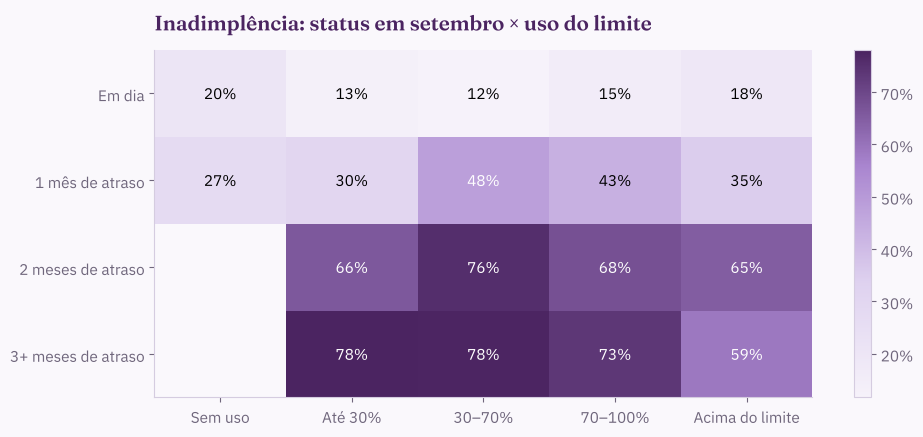

In [14]:
matriz = df.pivot_table(index='status_ultimo_mes', columns='faixa_uso_limite',
                        values='DEFAULT', aggfunc='mean', observed=True)

fig, ax = plt.subplots(figsize=(10, 4.5))
im = ax.imshow(matriz.values, cmap=CMAP_SEQ, aspect='auto')
ax.set_xticks(range(len(matriz.columns)), matriz.columns)
ax.set_yticks(range(len(matriz.index)), matriz.index)
ax.grid(False)
meio = (np.nanmin(matriz.values) + np.nanmax(matriz.values)) / 2
for i in range(matriz.shape[0]):
    for j in range(matriz.shape[1]):
        v = matriz.values[i, j]
        if not np.isnan(v):
            ax.text(j, i, f'{v:.0%}', ha='center', va='center', color='white' if v > meio else 'black')
ax.set_title('Inadimplência: status em setembro × uso do limite', loc='left', fontfamily=FONTE_TITULO)
plt.colorbar(im, format=mtick.PercentFormatter(1.0))
plt.tight_layout()
plt.savefig('images/09_status_x_uso_limite.png', dpi=120, bbox_inches='tight')
plt.show()

**Achado.** O status de pagamento domina: mesmo com uso baixo do limite, quem estava atrasado em setembro tem
inadimplência muito acima da média.

### 3.4 Limite de crédito

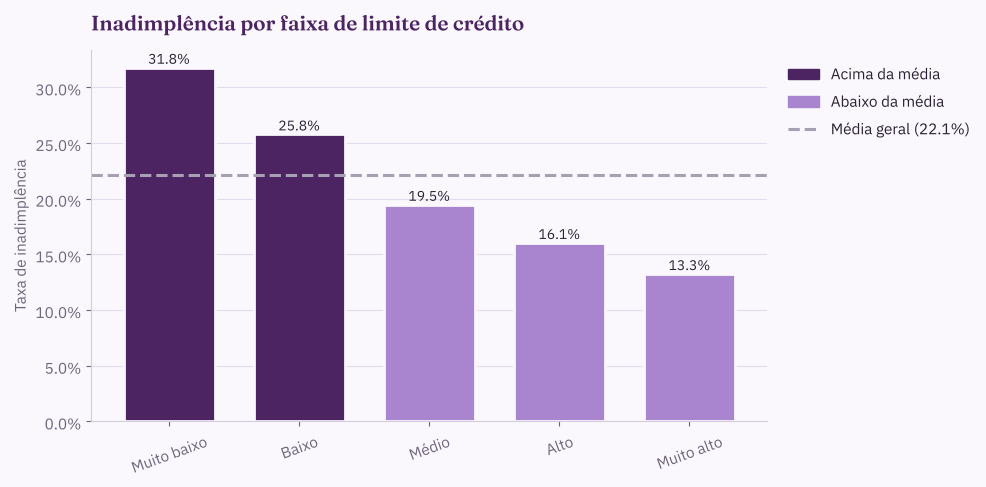

,taxa_inadimplencia,clientes,inadimplentes,risco_vs_media
faixa_limite,,,,
Muito baixo,31.8%,"7,676","2,440",1.44x
Baixo,25.8%,"4,822","1,244",1.17x
Médio,19.5%,"7,880","1,535",0.88x
Alto,16.1%,"5,059",812,0.73x
Muito alto,13.3%,"4,563",605,0.60x


In [15]:
taxa_por_grupo('faixa_limite', 'Inadimplência por faixa de limite de crédito', salvar='03_faixa_limite')

**Achado.** A inadimplência cai de forma consistente com o limite: 31,8% até NT\$ 50 mil e 13,3% acima de NT\$ 300 mil.
O banco já concede limites maiores a quem considera mais seguro, e os dados confirmam essa política. Como o dataset
não traz a renda, o limite também funciona como um indicador indireto da avaliação de crédito feita pelo banco,
que normalmente considera a renda além do histórico de pagamentos.

### 3.5 Dados cadastrais: idade e escolaridade
**Quantidade × taxa.** A quantidade mostra onde estão os inadimplentes; a taxa mostra o risco de cada grupo.

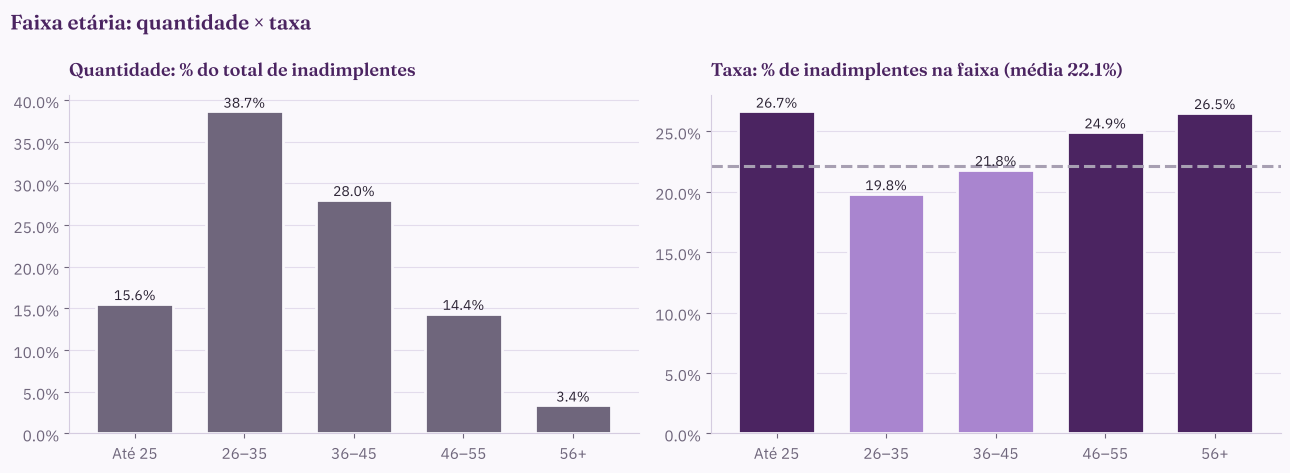

,clientes,inadimplentes,% dos inadimplentes,taxa de inadimplência
faixa_etaria,,,,
Até 25,"3,871","1,032",15.6%,26.7%
26–35,"12,938","2,565",38.7%,19.8%
36–45,"8,522","1,861",28.0%,21.8%
46–55,"3,825",954,14.4%,24.9%
56+,844,224,3.4%,26.5%


In [16]:
def quantidade_vs_taxa(coluna, titulo, salvar=None):
    """Mostra lado a lado a participação no total de inadimplentes e a taxa de inadimplência de cada grupo."""
    tabela = df.groupby(coluna, observed=True)['DEFAULT'].agg(clientes='count', inadimplentes='sum')
    tabela['% dos inadimplentes'] = tabela['inadimplentes'] / tabela['inadimplentes'].sum()
    tabela['taxa de inadimplência'] = tabela['inadimplentes'] / tabela['clientes']

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8))
    rot = 20 if max(len(str(r)) for r in tabela.index) > 8 else 0
    tabela['% dos inadimplentes'].plot(kind='bar', ax=ax1, color=TINTA_SUAVE, edgecolor=FUNDO, linewidth=2, width=0.7, rot=rot)
    ax1.set_title('Quantidade: % do total de inadimplentes', loc='left', fontfamily=FONTE_TITULO, fontsize=13)
    cores = [COR_ACIMA if t > taxa_geral else COR_ABAIXO for t in tabela['taxa de inadimplência']]
    tabela['taxa de inadimplência'].plot(kind='bar', ax=ax2, color=cores, edgecolor=FUNDO, linewidth=2, width=0.7, rot=rot)
    ax2.axhline(taxa_geral, color=CINZA, linestyle='--')
    ax2.set_title(f'Taxa: % de inadimplentes na faixa (média {taxa_geral:.1%})', loc='left', fontfamily=FONTE_TITULO, fontsize=13)
    for ax, col in [(ax1, '% dos inadimplentes'), (ax2, 'taxa de inadimplência')]:
        ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0)); ax.set_xlabel(''); ax.grid(axis='x', visible=False)
        for i, v in enumerate(tabela[col]):
            ax.text(i, v, f'{v:.1%}', ha='center', va='bottom', fontsize=10, color=TINTA)
    fig.suptitle(titulo, x=0.01, ha='left', fontsize=15, color=COR_TITULO, fontfamily=FONTE_TITULO)
    plt.tight_layout()
    if salvar:
        plt.savefig(f'images/{salvar}.png', dpi=120, bbox_inches='tight')
    plt.show()
    return tabela.style.format({'clientes': '{:,}', 'inadimplentes': '{:,}',
                                '% dos inadimplentes': '{:.1%}', 'taxa de inadimplência': '{:.1%}'})

quantidade_vs_taxa('faixa_etaria', 'Faixa etária: quantidade × taxa', salvar='03a_idade_quantidade_vs_taxa')

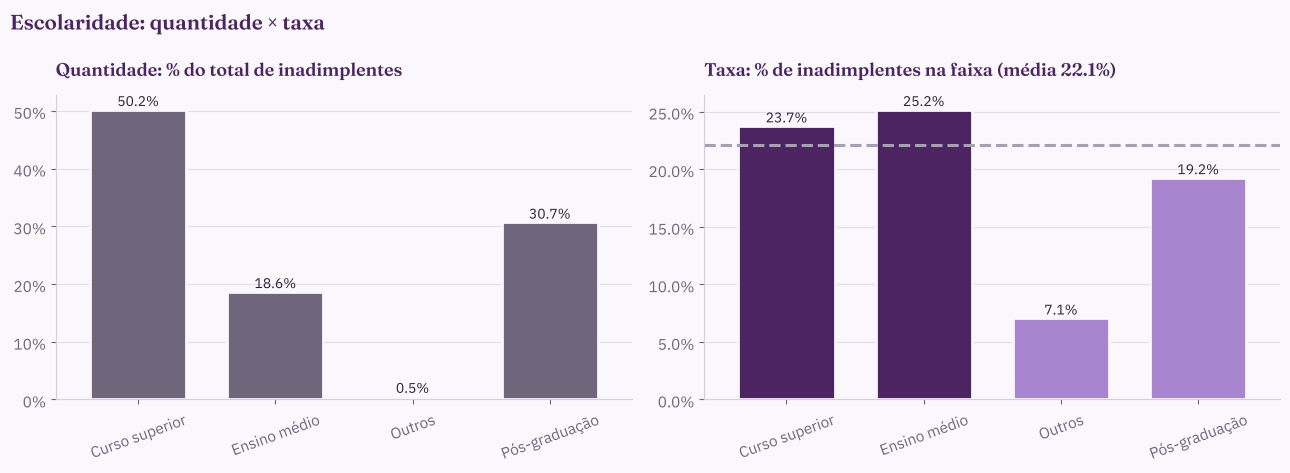

,clientes,inadimplentes,% dos inadimplentes,taxa de inadimplência
escolaridade,,,,
Curso superior,"14,030","3,330",50.2%,23.7%
Ensino médio,"4,917","1,237",18.6%,25.2%
Outros,468,33,0.5%,7.1%
Pós-graduação,"10,585","2,036",30.7%,19.2%


In [17]:
quantidade_vs_taxa('escolaridade', 'Escolaridade: quantidade × taxa', salvar='03b_escolaridade_quantidade_vs_taxa')

**Achado.** A faixa de 26 a 35 anos tem a maior quantidade de inadimplentes (38,7% do total), mas a menor taxa (19,8%):
ela só lidera porque concentra 43,1% dos clientes. As maiores taxas estão nas pontas, até 25 anos (26,7%) e 56+ (26,5%).

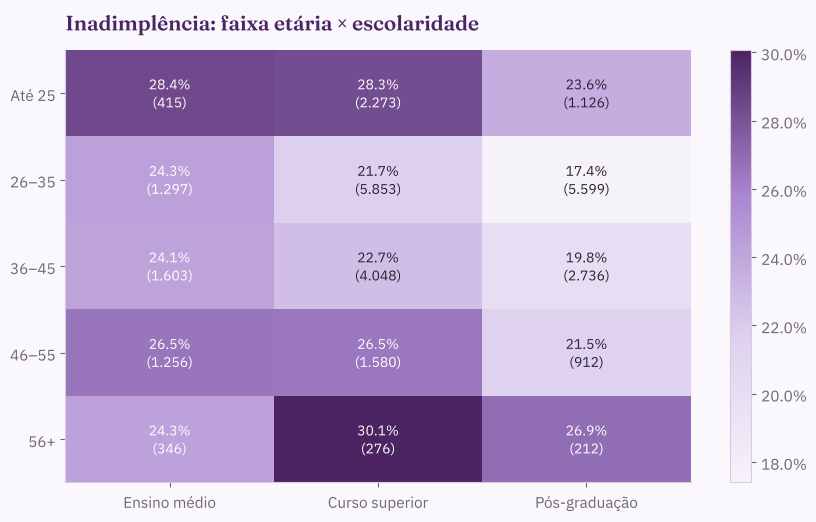

In [18]:
def mapa_taxa(linhas, colunas, dados, titulo, salvar=None):
    """Mapa de calor com a taxa de inadimplência e o número de clientes de cada combinação."""
    taxa = dados.pivot_table(index=linhas, columns=colunas, values='DEFAULT', aggfunc='mean', observed=True)
    n = dados.pivot_table(index=linhas, columns=colunas, values='DEFAULT', aggfunc='count', observed=True)
    fig, ax = plt.subplots(figsize=(1.9 * taxa.shape[1] + 3, 0.75 * taxa.shape[0] + 1.6))
    im = ax.imshow(taxa.values, cmap=CMAP_SEQ, aspect='auto')
    ax.set_xticks(range(taxa.shape[1]), taxa.columns); ax.set_yticks(range(taxa.shape[0]), taxa.index)
    ax.grid(False)
    meio = (np.nanmin(taxa.values) + np.nanmax(taxa.values)) / 2
    for i in range(taxa.shape[0]):
        for j in range(taxa.shape[1]):
            v = taxa.values[i, j]
            if not np.isnan(v):
                ax.text(j, i, f'{v:.1%}\n({int(n.values[i, j]):,})'.replace(',', '.'), ha='center', va='center',
                        fontsize=10, color='white' if v > meio else TINTA)
    ax.set_title(titulo, loc='left', fontfamily=FONTE_TITULO)
    plt.colorbar(im, format=mtick.PercentFormatter(1.0))
    plt.tight_layout()
    if salvar:
        plt.savefig(f'images/{salvar}.png', dpi=120, bbox_inches='tight')
    plt.show()
    return taxa

ordem_escolaridade = ['Ensino médio', 'Curso superior', 'Pós-graduação']
base_esc = df[df['escolaridade'].isin(ordem_escolaridade)].copy()
base_esc['escolaridade'] = pd.Categorical(base_esc['escolaridade'], ordem_escolaridade, ordered=True)
mapa_taxa('faixa_etaria', 'escolaridade', base_esc, 'Inadimplência: faixa etária × escolaridade',
          salvar='03c_idade_x_escolaridade');

**Achado.** A pós-graduação tem a menor taxa em todas as faixas até 55 anos. Ensino médio e curso superior ficam próximos.
A faixa 56+ tem poucos clientes e não segue o padrão.

**O risco dos jovens é da idade ou do limite?** Clientes de até 25 anos recebem limites bem menores (mediana de
NT\$ 50 mil, contra NT\$ 160 mil na faixa de 26 a 35). Para separar os dois efeitos, comparamos as idades dentro de
cada faixa de limite e calculamos a **taxa ajustada pelo limite** (padronização direta): a taxa que cada faixa etária
teria se recebesse limites na mesma proporção que a base inteira.

In [19]:
limite_por_idade = df.groupby('faixa_etaria', observed=True)['LIMIT_BAL'].agg(['median', 'mean']).rename(
    columns={'median': 'limite mediano (NT$)', 'mean': 'limite médio (NT$)'})
limite_por_idade.style.format('{:,.0f}')

,limite mediano (NT$),limite médio (NT$)
faixa_etaria,,
Até 25,"50,000","73,764"
26–35,"160,000","179,269"
36–45,"170,000","191,441"
46–55,"130,000","169,161"
56+,"130,000","167,192"


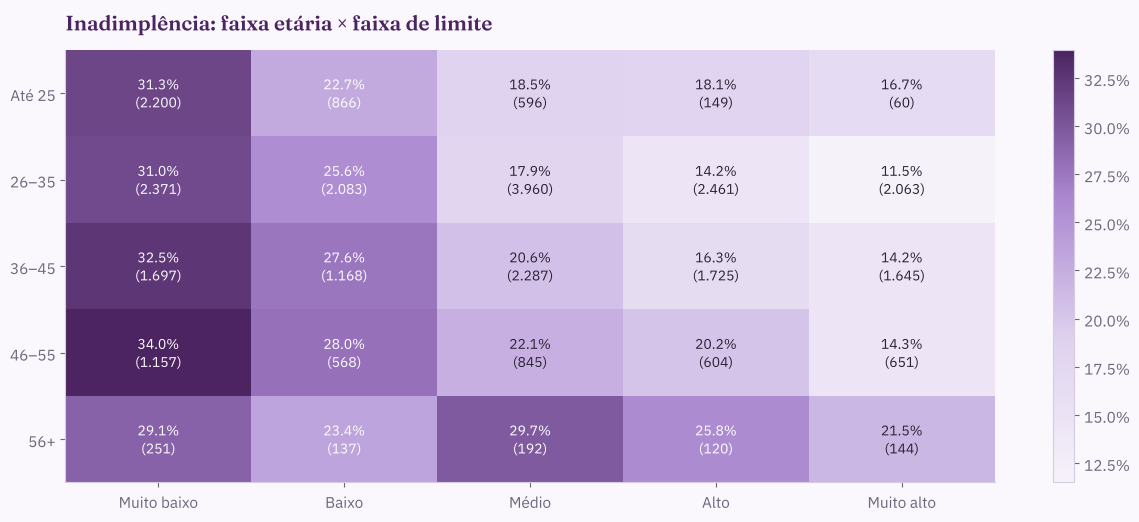

In [20]:
mapa_taxa('faixa_etaria', 'faixa_limite', df, 'Inadimplência: faixa etária × faixa de limite',
          salvar='03d_idade_x_limite');

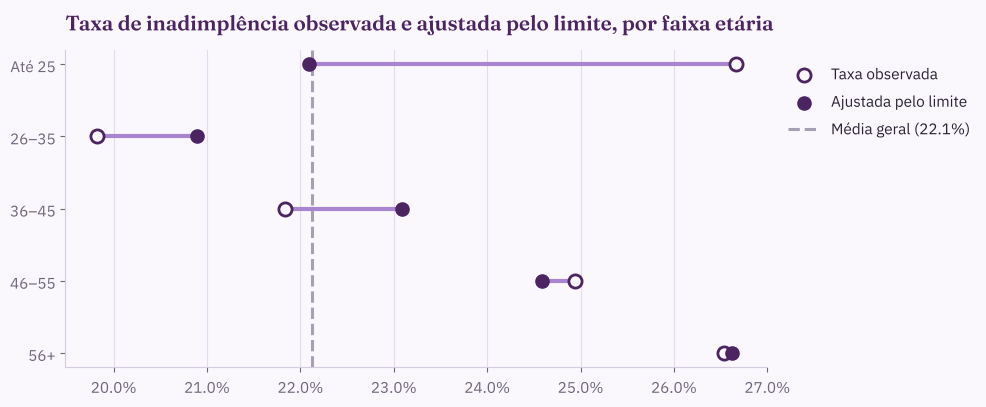

,taxa observada,taxa ajustada pelo limite
faixa_etaria,,
Até 25,26.7%,22.1%
26–35,19.8%,20.9%
36–45,21.8%,23.1%
46–55,24.9%,24.6%
56+,26.5%,26.6%


In [21]:
pesos_limite = df['faixa_limite'].value_counts(normalize=True)
taxa_idade_limite = df.pivot_table(index='faixa_etaria', columns='faixa_limite', values='DEFAULT', aggfunc='mean', observed=True)
ajuste = pd.DataFrame({
    'taxa observada': df.groupby('faixa_etaria', observed=True)['DEFAULT'].mean(),
    'taxa ajustada pelo limite': (taxa_idade_limite * pesos_limite.reindex(taxa_idade_limite.columns)).sum(axis=1),
})

fig, ax = plt.subplots(figsize=(10, 4.2))
y = np.arange(len(ajuste))[::-1]
for yi, (_, linha) in zip(y, ajuste.iterrows()):
    ax.plot([linha['taxa observada'], linha['taxa ajustada pelo limite']], [yi, yi], color=COR_ABAIXO, linewidth=3, zorder=1)
ax.scatter(ajuste['taxa observada'], y, s=90, facecolor=FUNDO, edgecolor=COR_ACIMA, linewidth=2, zorder=2, label='Taxa observada')
ax.scatter(ajuste['taxa ajustada pelo limite'], y, s=90, color=COR_ACIMA, zorder=3, label='Ajustada pelo limite')
ax.axvline(taxa_geral, color=CINZA, linestyle='--', label=f'Média geral ({taxa_geral:.1%})')
ax.set_yticks(y, ajuste.index); ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.grid(axis='y', visible=False); ax.grid(axis='x')
ax.set_title('Taxa de inadimplência observada e ajustada pelo limite, por faixa etária', loc='left', fontfamily=FONTE_TITULO)
ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.savefig('images/03f_taxa_ajustada_pelo_limite.png', dpi=120, bbox_inches='tight')
plt.show()
ajuste.style.format('{:.1%}')

**Achado.** Ajustando pelo limite, a taxa dos clientes de até 25 anos cai de 26,7% para 22,1%, igual à média geral.
Nas outras faixas, a mudança é pequena. O risco maior dos jovens é explicado pelos limites baixos que recebem
(**variável de confusão**). A faixa 56+ continua acima da média, mas tem poucos clientes.

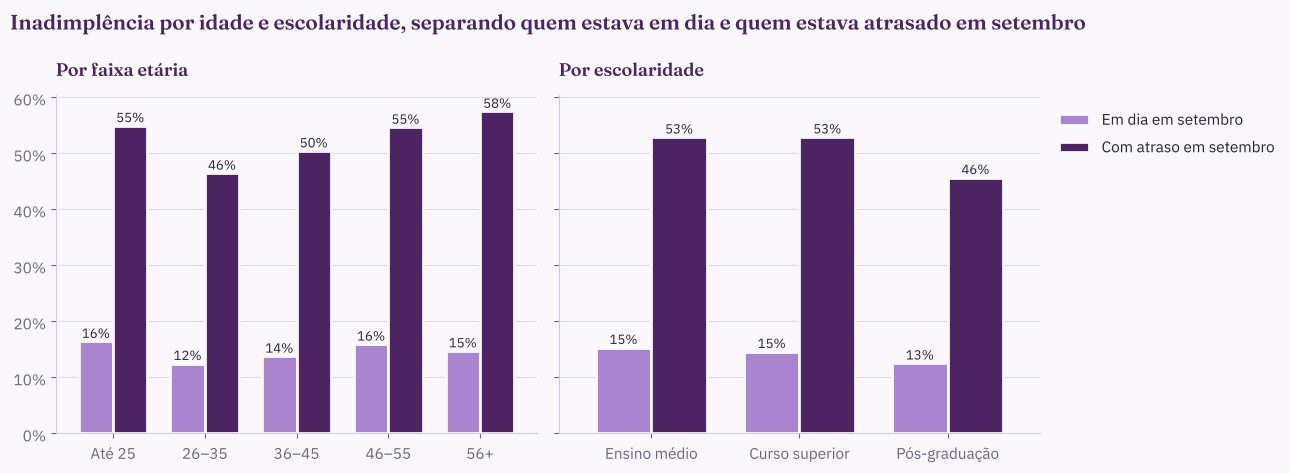

In [22]:
df['situacao_setembro'] = np.where(df['PAY_1'] > 0, 'Com atraso em setembro', 'Em dia em setembro')
base_esc['situacao_setembro'] = df.loc[base_esc.index, 'situacao_setembro']

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)   # mesma escala nos dois painéis
for ax, coluna, dados, titulo in [(ax1, 'faixa_etaria', df, 'Por faixa etária'),
                                  (ax2, 'escolaridade', base_esc, 'Por escolaridade')]:
    tabela = dados.pivot_table(index=coluna, columns='situacao_setembro', values='DEFAULT', aggfunc='mean', observed=True)
    tabela = tabela[['Em dia em setembro', 'Com atraso em setembro']]
    tabela.plot(kind='bar', ax=ax, color=[COR_ABAIXO, COR_ACIMA], edgecolor=FUNDO, linewidth=2, width=0.75, rot=0, legend=False)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0)); ax.set_xlabel(''); ax.grid(axis='x', visible=False)
    ax.set_title(titulo, loc='left', fontfamily=FONTE_TITULO, fontsize=13)
    for barras in ax.containers:
        ax.bar_label(barras, labels=[f'{v:.0%}' for v in barras.datavalues], fontsize=9.5, color=TINTA)
ax2.legend(loc='upper left', bbox_to_anchor=(1.01, 1))
fig.suptitle('Inadimplência por idade e escolaridade, separando quem estava em dia e quem estava atrasado em setembro',
             x=0.01, ha='left', fontsize=15, color=COR_TITULO, fontfamily=FONTE_TITULO)
plt.tight_layout()
plt.savefig('images/03e_perfil_controlando_historico.png', dpi=120, bbox_inches='tight')
plt.show()

**Achado.** Com o mesmo comportamento de pagamento, os dados cadastrais pesam pouco: entre quem estava em dia em
setembro, a inadimplência fica entre 12% e 16% em todas as faixas de idade e escolaridade; entre quem estava atrasado, entre 46% e 58%. A escolaridade
ainda traz alguma informação (pós-graduação um pouco abaixo), mas bem menos que o histórico.

## 4. Modelo preditivo

**Regressão logística** para estimar a probabilidade de inadimplência de cada cliente, com divisão de 70% para treino
e 30% para teste, e `class_weight='balanced'` para compensar o desbalanceamento (22% de inadimplentes).

**Escolha das variáveis.** Foram usados os indicadores criados (meses em atraso, status de setembro, uso do limite,
percentual da fatura paga, limite, idade e escolaridade) em vez dos 6 meses separados, para evitar multicolinearidade.
**Sexo e estado civil foram excluídos:** usá-los em decisões de crédito pode ser discriminatório e é restrito por lei
em vários países.

In [23]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, confusion_matrix, classification_report, roc_curve

df['pct_fatura_paga_lim'] = df['pct_fatura_paga'].clip(upper=1)   # quem pagou mais que a fatura conta como 100%

var_numericas = ['LIMIT_BAL', 'AGE', 'uso_limite', 'meses_em_atraso', 'atraso_mes_1',
                 'pct_fatura_paga_lim', 'sem_fatura']
var_categoricas = ['escolaridade']

X = df[var_numericas + var_categoricas]
y = df['DEFAULT']
X_treino, X_teste, y_treino, y_teste = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

preparacao = ColumnTransformer([
    ('num', Pipeline([('nulos', SimpleImputer(strategy='median')), ('escala', StandardScaler())]), var_numericas),
    # drop=['Ensino médio'] usa Ensino médio como categoria de referência: as demais são comparadas com ela
    ('cat', OneHotEncoder(handle_unknown='ignore', drop=['Ensino médio']), var_categoricas),
])

modelo = Pipeline([
    ('preparacao', preparacao),
    # class_weight='balanced' compensa o fato de existirem menos inadimplentes
    ('regressao', LogisticRegression(max_iter=1000, class_weight='balanced')),
])
modelo.fit(X_treino, y_treino)
print(f'Modelo treinado com {len(X_treino):,} clientes; teste com {len(X_teste):,}')

Modelo treinado com 21,000 clientes; teste com 9,000


AUC no teste: 0.755

              precision    recall  f1-score   support

  Adimplente       0.87      0.83      0.85      7009
Inadimplente       0.48      0.56      0.52      1991

    accuracy                           0.77      9000
   macro avg       0.67      0.69      0.68      9000
weighted avg       0.78      0.77      0.78      9000



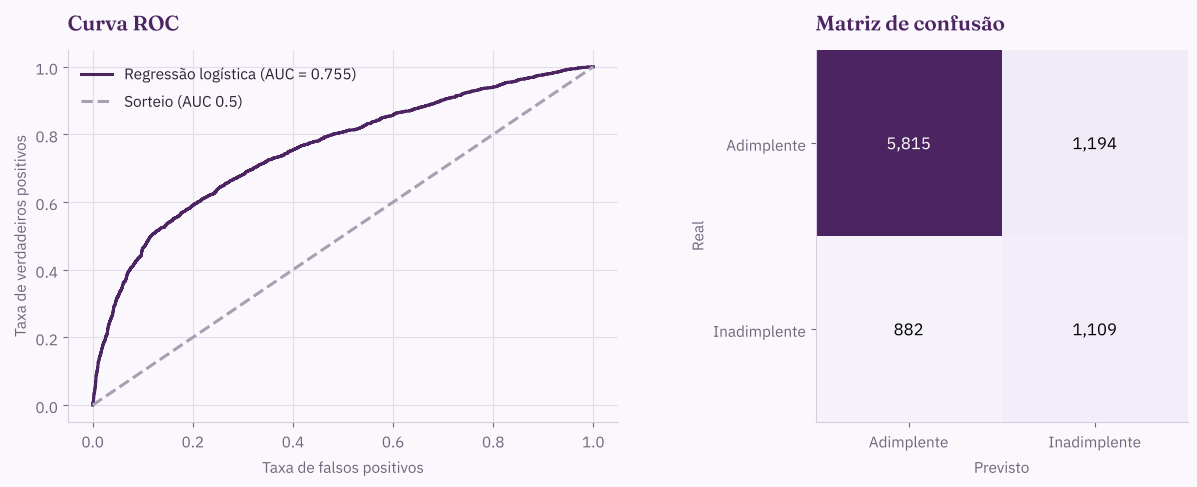

In [24]:
prob_teste = modelo.predict_proba(X_teste)[:, 1]
pred_teste = modelo.predict(X_teste)

auc = roc_auc_score(y_teste, prob_teste)
print(f'AUC no teste: {auc:.3f}\n')
print(classification_report(y_teste, pred_teste, target_names=['Adimplente', 'Inadimplente']))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fpr, tpr, _ = roc_curve(y_teste, prob_teste)
axes[0].plot(fpr, tpr, color=COR_ACIMA, label=f'Regressão logística (AUC = {auc:.3f})')
axes[0].plot([0, 1], [0, 1], '--', color=CINZA, label='Sorteio (AUC 0.5)'); axes[0].legend()
axes[0].grid(axis='x')
axes[0].set_title('Curva ROC', loc='left', fontfamily=FONTE_TITULO)
axes[0].set_xlabel('Taxa de falsos positivos'); axes[0].set_ylabel('Taxa de verdadeiros positivos')

cm = confusion_matrix(y_teste, pred_teste)
axes[1].imshow(cm, cmap=CMAP_SEQ); axes[1].grid(False)
rotulos = ['Adimplente', 'Inadimplente']
axes[1].set_xticks([0, 1], rotulos); axes[1].set_yticks([0, 1], rotulos)
axes[1].set_xlabel('Previsto'); axes[1].set_ylabel('Real')
for i in range(2):
    for j in range(2):
        axes[1].text(j, i, f'{cm[i, j]:,}', ha='center', va='center', fontsize=12,
                     color='white' if cm[i, j] > cm.max() / 2 else 'black')
axes[1].set_title('Matriz de confusão', loc='left', fontfamily=FONTE_TITULO)
plt.tight_layout()
plt.savefig('images/11_avaliacao_modelo.png', dpi=120, bbox_inches='tight')
plt.show()

**Resultado.** AUC de 0,755 no teste. O modelo identifica 56% dos inadimplentes (recall), e 48% dos clientes que ele
aponta como risco de fato ficam inadimplentes (precisão). Como só 22% dos clientes são inadimplentes, a acurácia
sozinha seria enganosa.

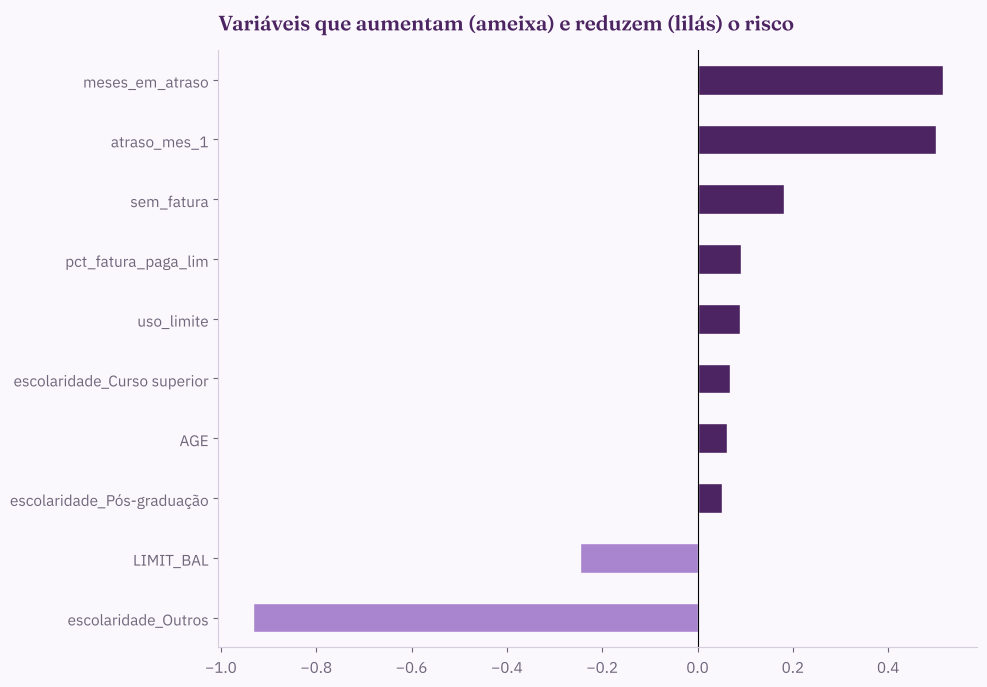

In [25]:
nomes = modelo.named_steps['preparacao'].get_feature_names_out()
coef = pd.Series(modelo.named_steps['regressao'].coef_[0], index=nomes)
coef.index = coef.index.str.replace('num__', '').str.replace('cat__', '')
coef = coef.sort_values()

ax = coef.plot(kind='barh', color=[COR_ABAIXO if v < 0 else COR_ACIMA for v in coef], edgecolor=FUNDO, figsize=(10, 7))
ax.grid(axis='x'); ax.grid(axis='y', visible=False)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_title(f'Variáveis que aumentam ({NOME_ACIMA}) e reduzem ({NOME_ABAIXO}) o risco', loc='left', fontfamily=FONTE_TITULO)
plt.tight_layout()
plt.savefig('images/12_importancia_variaveis.png', dpi=120, bbox_inches='tight')
plt.show()

**Leitura dos coeficientes.** Meses em atraso e o atraso em setembro são, de longe, as variáveis que mais aumentam o
risco; um limite maior reduz o risco. Os coeficientes consideram todas as variáveis ao mesmo tempo, por isso podem
diferir do efeito de cada uma isoladamente.

In [26]:
from sklearn.ensemble import RandomForestClassifier

floresta = Pipeline([
    ('preparacao', preparacao),
    ('floresta', RandomForestClassifier(n_estimators=300, max_depth=8, min_samples_leaf=20,
                                        class_weight='balanced', random_state=42, n_jobs=-1)),
])
floresta.fit(X_treino, y_treino)
auc_floresta = roc_auc_score(y_teste, floresta.predict_proba(X_teste)[:, 1])

print(f'AUC Regressão logística: {auc:.3f}')
print(f'AUC Random Forest:       {auc_floresta:.3f}')

AUC Regressão logística: 0.755
AUC Random Forest:       0.774


**Comparação.** A Random Forest chega a AUC de 0,774, um ganho pequeno. A regressão logística foi mantida como modelo
principal por ser mais fácil de explicar à área de negócio e a órgãos reguladores, algo importante em crédito.

## 5. Impacto no negócio
Os clientes de teste são ordenados do mais arriscado ao menos arriscado. A pergunta é: se o banco agir sobre os X%
mais arriscados, quantos inadimplentes alcança e quanto do saldo em risco cobre?

In [27]:
resultado = pd.DataFrame({
    'real': y_teste.values,
    'prob': prob_teste,
    'saldo': df.loc[X_teste.index, 'BILL_AMT1'].clip(lower=0).values,
}).sort_values('prob', ascending=False).reset_index(drop=True)

total_inad  = resultado['real'].sum()
saldo_risco = resultado.loc[resultado['real'] == 1, 'saldo'].sum()

linhas = []
for pct in [5, 10, 20, 30, 40]:
    grupo = resultado.head(int(len(resultado) * pct / 100))
    linhas.append({
        'Clientes priorizados': f'{pct}% mais arriscados',
        '% dos inadimplentes alcançados': grupo['real'].sum() / total_inad,
        '% do saldo em risco coberto': grupo.loc[grupo['real'] == 1, 'saldo'].sum() / saldo_risco,
        'Inadimplência dentro do grupo': grupo['real'].mean(),
    })
impacto = pd.DataFrame(linhas)
print(f'Saldo total em risco na base de teste: NT$ {saldo_risco:,.0f}')
impacto.style.format({c: '{:.1%}' for c in impacto.columns[1:]}).hide(axis='index')

Saldo total em risco na base de teste: NT$ 100,094,195


Clientes priorizados,% dos inadimplentes alcançados,% do saldo em risco coberto,Inadimplência dentro do grupo
5% mais arriscados,16.3%,16.4%,72.0%
10% mais arriscados,29.5%,31.0%,65.3%
20% mais arriscados,49.7%,52.5%,55.0%
30% mais arriscados,60.2%,58.2%,44.4%
40% mais arriscados,69.6%,63.5%,38.5%


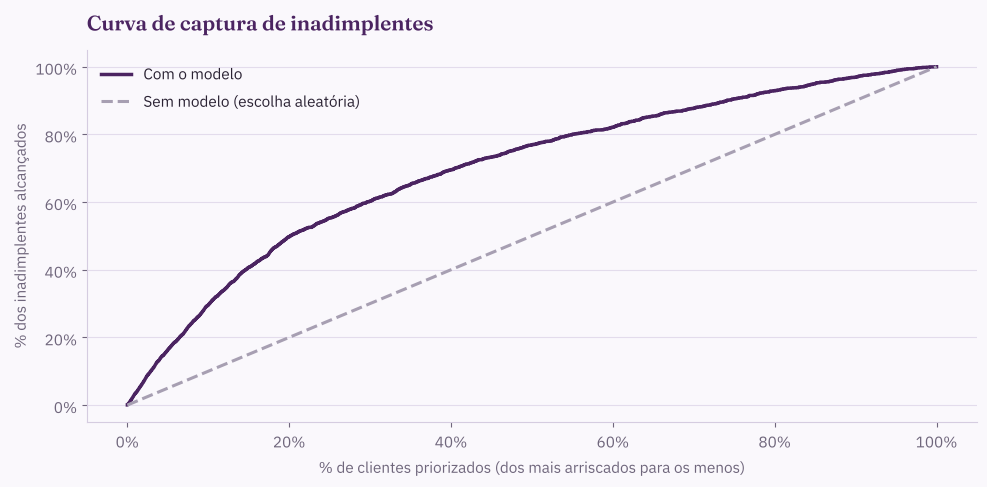

In [28]:
# Curva de captura: quanto dos inadimplentes é alcançado conforme aumentamos o grupo priorizado
captura = resultado['real'].cumsum() / total_inad
pct_clientes = np.arange(1, len(resultado) + 1) / len(resultado)

fig, ax = plt.subplots()
ax.plot(pct_clientes, captura, color=COR_ACIMA, linewidth=2.5, label='Com o modelo')
ax.plot([0, 1], [0, 1], '--', color=CINZA, label='Sem modelo (escolha aleatória)')
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_xlabel('% de clientes priorizados (dos mais arriscados para os menos)')
ax.set_ylabel('% dos inadimplentes alcançados')
ax.set_title('Curva de captura de inadimplentes', loc='left', fontfamily=FONTE_TITULO)
ax.legend(); plt.tight_layout()
plt.savefig('images/13_curva_captura.png', dpi=120, bbox_inches='tight')
plt.show()

**Achado.** Priorizando os 20% de clientes de maior risco, o banco alcança **49,7% dos inadimplentes** e 52,5% do saldo
em risco. Sem o modelo, alcançaria apenas 20%. Nos 5% mais arriscados, 72% dos clientes ficam de fato inadimplentes.

## 6. Conclusões e recomendações

**Conclusões**
1. O **comportamento de pagamento** é o fator mais importante: o atraso recente e a frequência de atrasos separam bons e maus pagadores muito melhor que os dados cadastrais.
2. Os sinais de risco aparecem **meses antes** da inadimplência, o que dá tempo para agir.
3. **Limites baixos, uso acima do limite e pagamento parcial** da fatura também indicam risco.
4. Os dados cadastrais têm efeito pequeno quando se considera limite e histórico. O risco maior dos jovens vem, em boa parte, dos limites menores.
5. Um modelo simples e explicável já permite **priorizar** quase metade dos inadimplentes olhando só para 20% da carteira.

**Recomendações**
- **Cobrança preventiva no primeiro mês de atraso:** clientes com 1 mês de atraso já têm 33,9% de inadimplência (1,5 vez a média).
- **Priorização pelo modelo:** concentrar cobrança e revisão de limite nos 20% de maior risco.
- **Renegociação** para quem paga menos de 10% da fatura, antes que o atraso aconteça.

**Limitações e próximos passos**
- Dados de 2005, de um único banco de Taiwan: os padrões podem não valer para o Brasil hoje.
- Não há renda, profissão ou dados de outros produtos, o que limita a análise de capacidade de pagamento.
- Próximos passos: testar modelos de gradient boosting, definir o ponto de corte pelo custo de cada erro e monitorar o modelo ao longo do tempo.

---
**Referência:** Yeh, I. (2009). *Default of Credit Card Clients* [Dataset]. UCI Machine Learning Repository.
https://doi.org/10.24432/C55S3H, licença CC BY 4.0.